In [4]:
!mamba install pandas
!mamba install seaborn
!mamba install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import kruskal

sns.set_theme(style="whitegrid")

df = pd.read_csv("spotify_cluster_cleaned.csv")
X = pd.read_csv("spotify_cluster_scaled.csv")

features = [
    "acousticness",
    "danceability",
    "duration_ms",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence"
]

X = X[features]

print("Cleaned dataset:", df.shape)
print("Scaled dataset:", X.shape)

X.head()

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.537 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.469 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.544 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ ca-certificates     2026.11.20  hbd8a1cb_0           conda-forge
+ certifi             2026.11.20  pyhd8ed1ab_0         conda-f

,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
0,-0.875177,0.644260,0.013495,-0.675976,-0.535478,0.723666,0.335731,0.490464,-1.133609,0.934036
1,1.760797,-0.804604,-0.704151,-1.825609,-0.535464,-0.595072,-1.673094,-0.098361,-1.479854,-0.770280
2,-0.349638,-0.702731,-0.162163,-1.073476,-0.535481,-0.512971,-0.236523,-0.280217,-1.518271,-1.329508
3,1.704637,-1.676186,-0.240899,-2.240257,-0.535263,-0.436002,-1.918236,-0.451480,1.981637,-1.242010
4,0.415912,0.316001,-0.268168,-0.746123,-0.535481,-0.687948,-0.226373,-0.307584,-0.070037,-1.150708


In [5]:
assert len(df) == len(X)
assert df["track_id"].is_unique
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()
assert df["popularity"].between(0, 100).all()

# Verify that the scaled rows match the cleaned rows
expected_scaled = StandardScaler().fit_transform(df[features])

assert np.allclose(X.to_numpy(), expected_scaled)

validation = pd.DataFrame({
    "Missing values": X.isna().sum(),
    "Mean": X.mean(),
    "Standard deviation": X.std(ddof=0),
    "Minimum": X.min(),
    "Maximum": X.max()
})

print("All validation checks passed.")
display(validation.round(3))

All validation checks passed.


,Missing values,Mean,Standard deviation,Minimum,Maximum
acousticness,0,0.0,1.0,-0.970,1.974
danceability,0,-0.0,1.0,-3.182,2.393
duration_ms,0,0.0,1.0,-2.029,44.341
energy,0,0.0,1.0,-2.473,1.425
instrumentalness,0,-0.0,1.0,-0.535,2.552
liveness,0,-0.0,1.0,-1.113,4.018
loudness,0,-0.0,1.0,-7.858,2.496
speechiness,0,0.0,1.0,-0.772,7.747
tempo,0,-0.0,1.0,-4.053,4.028
valence,0,0.0,1.0,-1.786,1.999


In [6]:
k_values = range(2, 11)

inertias = []
silhouette_scores = []
models = {}

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertia = model.inertia_

    silhouette = silhouette_score(
        X,
        labels,
        sample_size=5000,
        random_state=42
    )

    inertias.append(inertia)
    silhouette_scores.append(silhouette)
    models[k] = model

    print(
        f"K = {k} | "
        f"Inertia = {inertia:.2f} | "
        f"Silhouette = {silhouette:.4f}"
    )

evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(evaluation)

/lib/python3.13/site-packages/threadpoolctl.py:1932: UserWarning: Unable to import LDSO from pyodide_js._module. This should never happen.
  warnings.warn(


K = 2 | Inertia = 722275.34 | Silhouette = 0.2539
K = 3 | Inertia = 648779.45 | Silhouette = 0.1531
K = 4 | Inertia = 592782.28 | Silhouette = 0.1597
K = 5 | Inertia = 543060.82 | Silhouette = 0.1621
K = 6 | Inertia = 500392.89 | Silhouette = 0.1680
K = 7 | Inertia = 462454.08 | Silhouette = 0.1740
K = 8 | Inertia = 438997.62 | Silhouette = 0.1748
K = 9 | Inertia = 418280.03 | Silhouette = 0.1591
K = 10 | Inertia = 403316.31 | Silhouette = 0.1463


,K,Inertia,Silhouette Score
0,2,722275.341054,0.253937
1,3,648779.450554,0.153112
2,4,592782.275134,0.159721
3,5,543060.816612,0.162059
4,6,500392.885553,0.168034
5,7,462454.079906,0.173953
6,8,438997.617781,0.174845
7,9,418280.025360,0.159060
8,10,403316.313857,0.146293


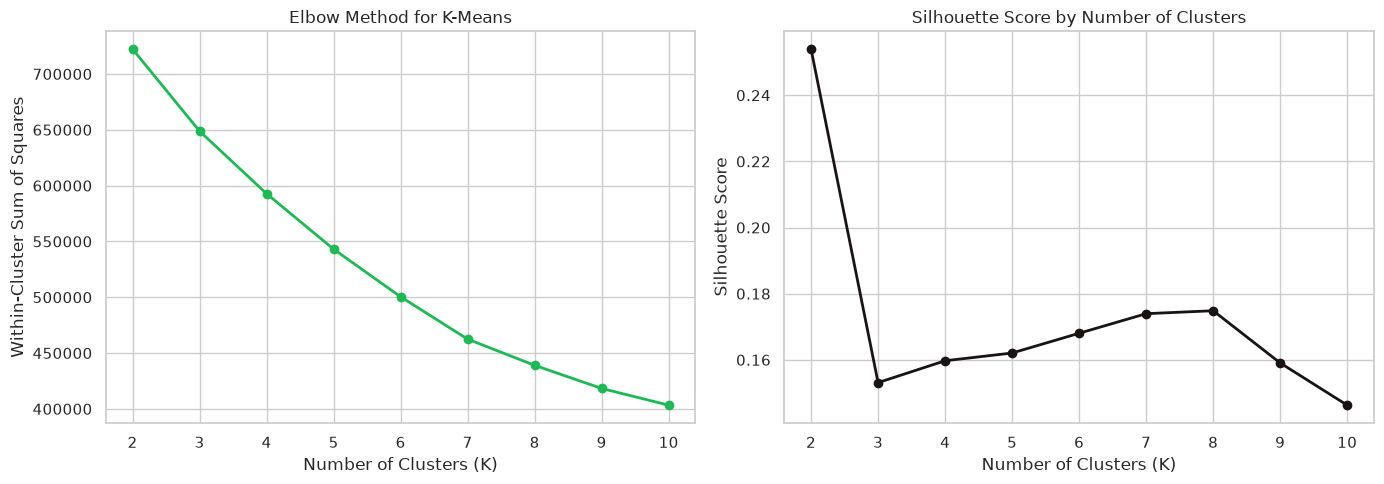

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(
    k_values,
    inertias,
    marker="o",
    color="#1DB954",
    linewidth=2
)

axes[0].set_title("Elbow Method for K-Means")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Within-Cluster Sum of Squares")
axes[0].set_xticks(list(k_values))

# Silhouette plot
axes[1].plot(
    k_values,
    silhouette_scores,
    marker="o",
    color="#191414",
    linewidth=2
)

axes[1].set_title("Silhouette Score by Number of Clusters")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

In [8]:
best_k = int(
    evaluation.loc[
        evaluation["Silhouette Score"].idxmax(), "K"
    ]
)

print("Suggested number of clusters:", best_k)

# Change best_k here if justified by the evaluation

kmeans = models[best_k]

df["cluster"] = kmeans.labels_ + 1

X_clustered = X.copy()
X_clustered["cluster"] = df["cluster"]

cluster_sizes = df["cluster"].value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "Number of Songs": cluster_sizes,
    "Percentage": cluster_sizes / len(df) * 100
})

display(cluster_summary.round(2))

Suggested number of clusters: 2


,Number of Songs,Percentage
cluster,,
1,67499,75.22
2,22242,24.78


,mean,median,std,min,max
cluster,,,,,
1,0.2798,0.2954,0.1072,0.0186,0.4642
2,0.1764,0.1818,0.1181,-0.0511,0.3925


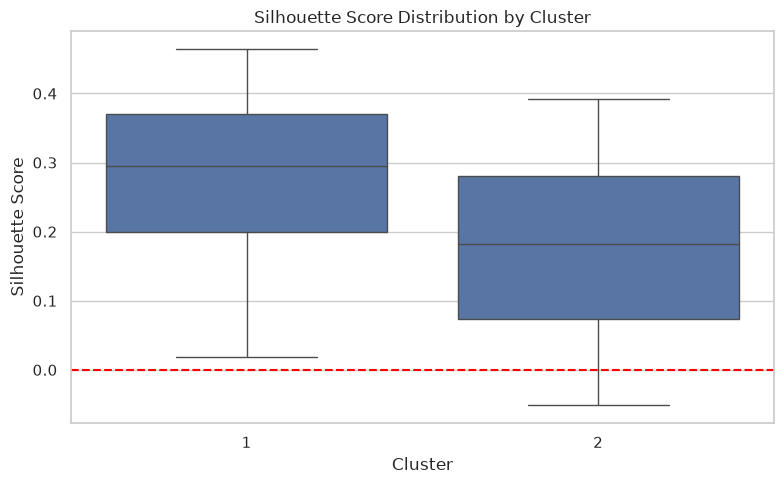

In [9]:
from sklearn.metrics import silhouette_samples

sample_indices = X.sample(
    n=5000,
    random_state=42
).index

X_silhouette = X.loc[sample_indices]
labels_silhouette = df.loc[sample_indices, "cluster"]

silhouette_values = silhouette_samples(
    X_silhouette,
    labels_silhouette
)

silhouette_df = pd.DataFrame({
    "cluster": labels_silhouette.to_numpy(),
    "silhouette": silhouette_values
})

display(
    silhouette_df.groupby("cluster")["silhouette"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(4)
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=silhouette_df,
    x="cluster",
    y="silhouette"
)

plt.axhline(0, color="red", linestyle="--")
plt.title("Silhouette Score Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

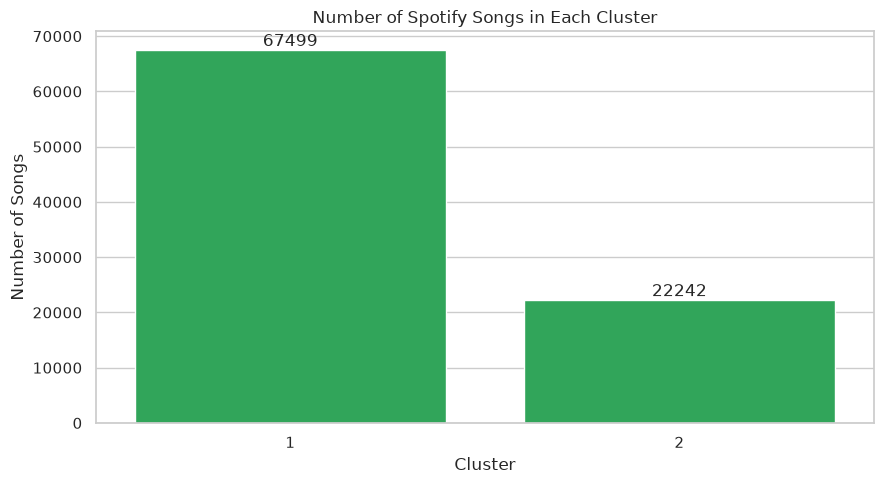

In [10]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="cluster",
    color="#1DB954"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.title("Number of Spotify Songs in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
Cluster,,,,,,,,,,
1,-0.41,0.19,0.03,0.44,-0.16,0.06,0.38,0.08,0.14,0.20
2,1.26,-0.58,-0.10,-1.32,0.48,-0.18,-1.17,-0.25,-0.42,-0.62


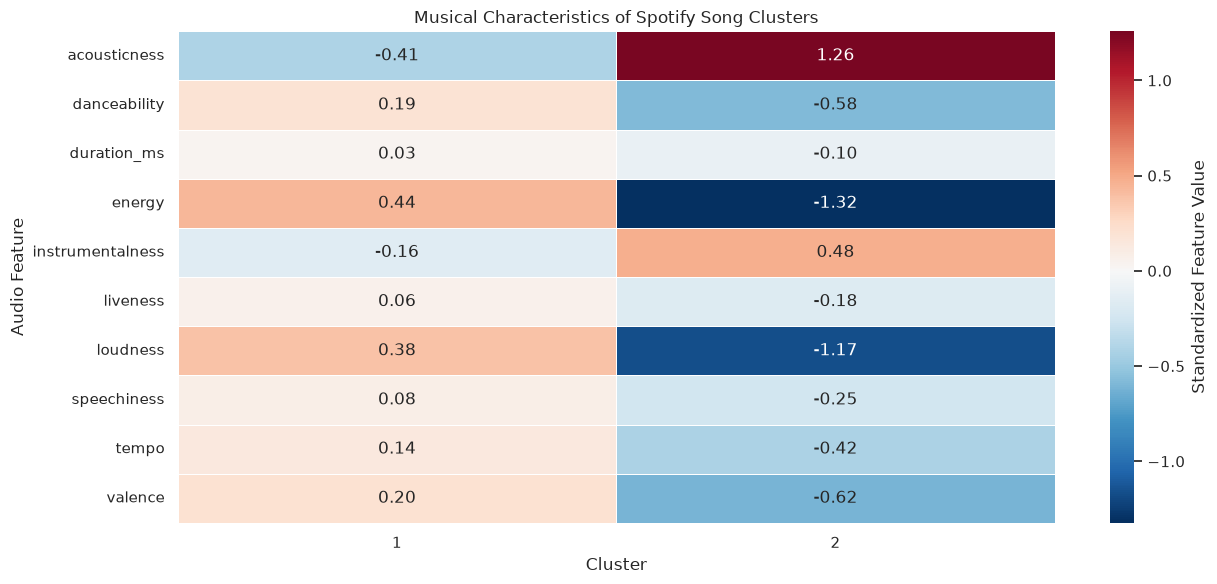

In [11]:
cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features,
    index=range(1, best_k + 1)
)

cluster_centers.index.name = "Cluster"

display(cluster_centers.round(2))

plt.figure(figsize=(13, 6))

sns.heatmap(
    cluster_centers.T,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Standardized Feature Value"}
)

plt.title("Musical Characteristics of Spotify Song Clusters")
plt.xlabel("Cluster")
plt.ylabel("Audio Feature")

plt.tight_layout()
plt.show()

In [12]:
original_centers = df.groupby("cluster")[features].mean()

original_centers["duration_minutes"] = (
    original_centers["duration_ms"] / 60000
)

original_centers = original_centers.drop(
    columns="duration_ms"
)

display(original_centers.round(3))

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_minutes
cluster,,,,,,,,,,
1,0.188,0.596,0.746,0.123,0.229,-6.490,0.097,126.272,0.523,3.880
2,0.753,0.460,0.295,0.328,0.182,-14.595,0.059,109.270,0.307,3.633


In [13]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["cluster"] = df["cluster"]

variance = pca.explained_variance_ratio_

print(f"PC1 explained variance: {variance[0]:.2%}")
print(f"PC2 explained variance: {variance[1]:.2%}")
print(f"Total explained variance: {variance.sum():.2%}")

pca_df.head()

PC1 explained variance: 28.91%
PC2 explained variance: 15.22%
Total explained variance: 44.12%


,PC1,PC2,cluster
0,0.688203,1.008546,1
1,-3.182117,1.306280,2
2,-1.315153,-0.170263,2
3,-3.186998,-0.240363,2
4,-0.884284,0.302655,2


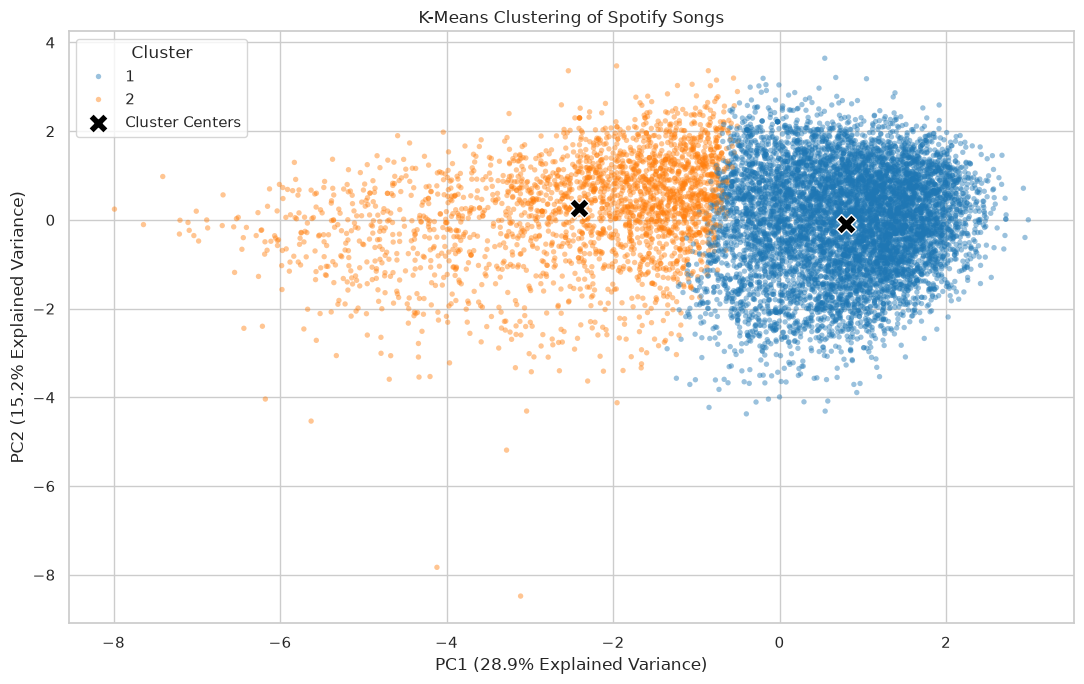

In [14]:
# Sample observations to avoid excessive overplotting
plot_df = pca_df.sample(
    n=min(10000, len(pca_df)),
    random_state=42
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.45,
    s=15,
    linewidth=0
)

# Project cluster centers into PCA space
centers_pca = pca.transform(
    pd.DataFrame(
        kmeans.cluster_centers_,
        columns=features
    )
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=200,
    c="black",
    edgecolors="white",
    label="Cluster Centers"
)

plt.title("K-Means Clustering of Spotify Songs")
plt.xlabel(f"PC1 ({variance[0]:.1%} Explained Variance)")
plt.ylabel(f"PC2 ({variance[1]:.1%} Explained Variance)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

,PC1,PC2
acousticness,-0.433,0.331
danceability,0.258,0.473
duration_ms,-0.008,-0.398
energy,0.504,-0.271
instrumentalness,-0.283,-0.331
liveness,0.084,-0.135
loudness,0.514,-0.077
speechiness,0.097,0.102
tempo,0.201,-0.224
valence,0.300,0.491


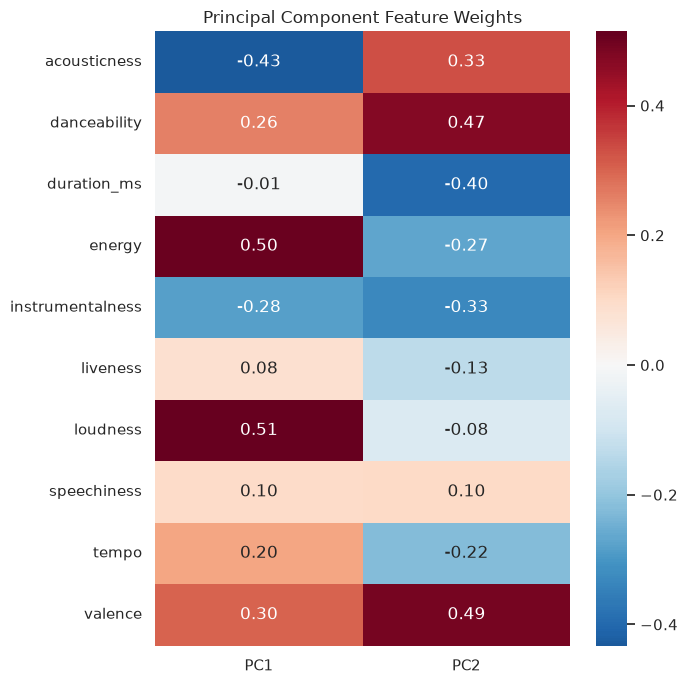

In [15]:
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

display(pca_loadings.round(3))

plt.figure(figsize=(7, 7))

sns.heatmap(
    pca_loadings,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Principal Component Feature Weights")

plt.tight_layout()
plt.show()

In [16]:
popularity_summary = df.groupby("cluster")["popularity"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max"
)

popularity_summary["Q1"] = (
    df.groupby("cluster")["popularity"].quantile(0.25)
)

popularity_summary["Q3"] = (
    df.groupby("cluster")["popularity"].quantile(0.75)
)

popularity_summary["IQR"] = (
    popularity_summary["Q3"] -
    popularity_summary["Q1"]
)

popularity_summary = popularity_summary.sort_values(
    "mean",
    ascending=False
)

display(popularity_summary.round(2))

,count,mean,median,std,minimum,maximum,Q1,Q3,IQR
cluster,,,,,,,,,
1,67499,33.97,34.0,20.58,0,100,20.0,49.0,29.0
2,22242,30.86,29.0,20.41,0,94,17.0,47.0,30.0


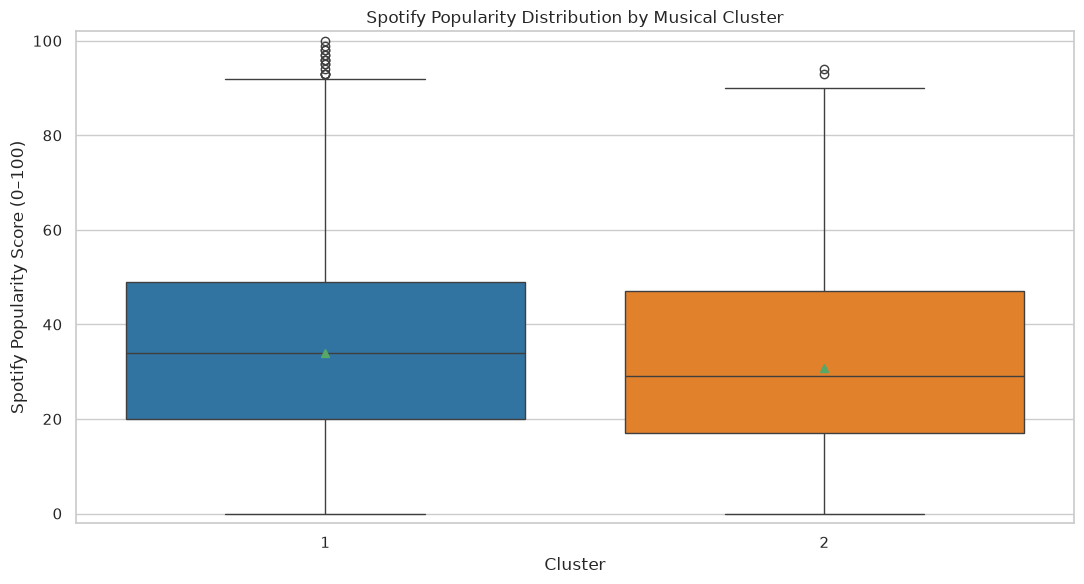

In [17]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="cluster",
    y="popularity",
    hue="cluster",
    palette="tab10",
    legend=False,
    showmeans=True
)

plt.title("Spotify Popularity Distribution by Musical Cluster")
plt.xlabel("Cluster")
plt.ylabel("Spotify Popularity Score (0–100)")
plt.ylim(-2, 102)

plt.tight_layout()
plt.show()

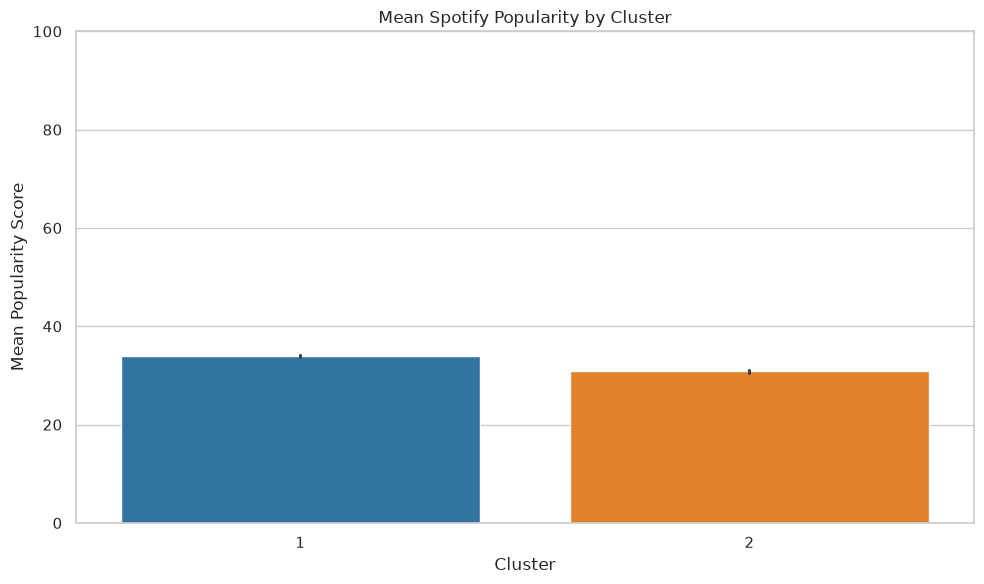

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="cluster",
    y="popularity",
    hue="cluster",
    palette="tab10",
    legend=False,
    errorbar=("ci", 95),
    n_boot=1000,
    seed=42
)

plt.title("Mean Spotify Popularity by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean Popularity Score")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [19]:
groups = [
    df.loc[df["cluster"] == cluster, "popularity"]
    for cluster in sorted(df["cluster"].unique())
]

h_stat, p_value = kruskal(*groups)

n = len(df)
k = len(groups)

# Rank-based effect size
effect_size = max(0, (h_stat - k + 1) / (n - k))

print(f"Kruskal-Wallis statistic: {h_stat:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Rank-based effect size: {effect_size:.4f}")

if p_value < 0.05:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

mean_difference = (
    popularity_summary["mean"].max() -
    popularity_summary["mean"].min()
)

print(
    f"Difference between highest and lowest "
    f"cluster mean popularity: {mean_difference:.2f}"
)

Kruskal-Wallis statistic: 339.6484
P-value: 7.6110e-76
Rank-based effect size: 0.0038
Reject the null hypothesis.
Difference between highest and lowest cluster mean popularity: 3.11


In [20]:
genre_counts = pd.crosstab(
    df["cluster"],
    df["track_genre"]
)

genre_proportions = pd.crosstab(
    df["cluster"],
    df["track_genre"],
    normalize="index"
) * 100

for cluster in sorted(df["cluster"].unique()):

    print(f"\nCluster {cluster}: Top 5 Genres")

    top_genres = (
        genre_proportions.loc[cluster]
        .sort_values(ascending=False)
        .head(5)
    )

    display(top_genres.round(2))


Cluster 1: Top 5 Genres


track_genre
happy            1.47
forro            1.47
breakbeat        1.47
chicago-house    1.45
heavy-metal      1.45
Name: 1, dtype: float64


Cluster 2: Top 5 Genres


track_genre
sleep        4.33
ambient      4.05
new-age      3.99
romance      3.60
classical    3.60
Name: 2, dtype: float64

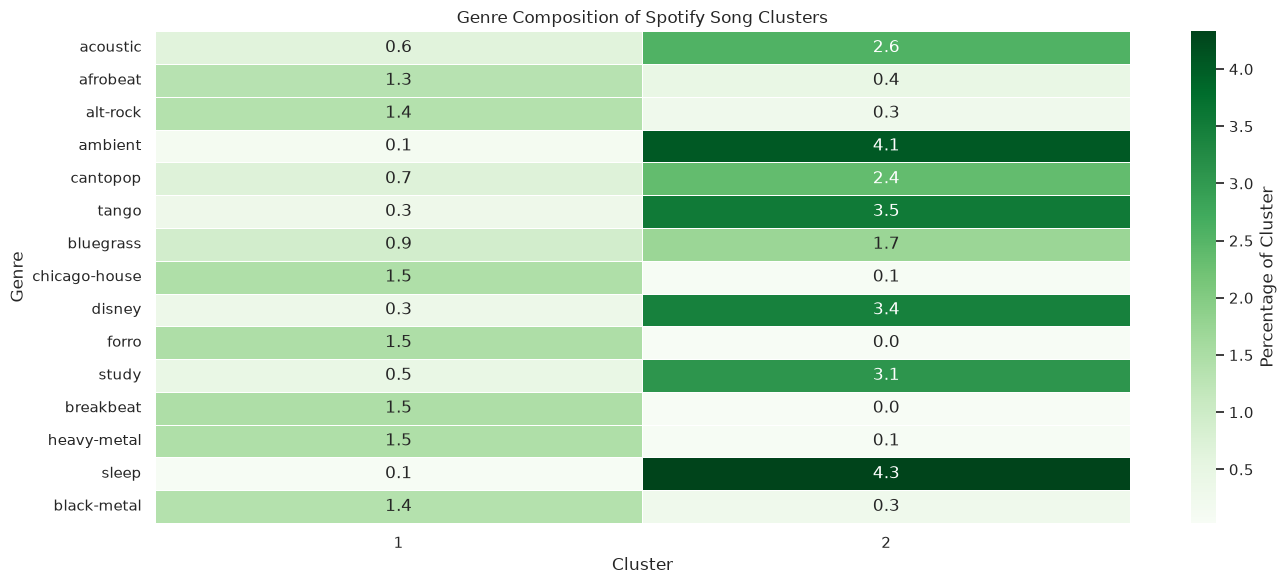

In [21]:
top_genres = (
    df["track_genre"]
    .value_counts()
    .head(15)
    .index
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    genre_proportions[top_genres].T,
    annot=True,
    fmt=".1f",
    cmap="Greens",
    linewidths=0.5,
    cbar_kws={"label": "Percentage of Cluster"}
)

plt.title("Genre Composition of Spotify Song Clusters")
plt.xlabel("Cluster")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [22]:
distances = kmeans.transform(X)

df["distance_to_center"] = distances[
    np.arange(len(df)),
    kmeans.labels_
]

for cluster in sorted(df["cluster"].unique()):

    representative_songs = (
        df[df["cluster"] == cluster]
        .nsmallest(5, "distance_to_center")
    )

    print(f"\nCluster {cluster}: Representative Songs")

    display(
        representative_songs[
            [
                "track_name",
                "artists",
                "track_genre",
                "popularity",
                "distance_to_center"
            ]
        ]
    )


Cluster 1: Representative Songs


,track_name,artists,track_genre,popularity,distance_to_center
58539,Third Eye Freeverse (Red Bull 64 Bars),Hanumankind;Karan Kanchan,malay,27,0.717857
88063,Aynalarımda,Stabil;Bedo,turkish,46,0.729327
89249,En Tempestad,Planetshakers,world-music,27,0.765896
84841,Эшафот,Electroforez,synth-pop,34,0.778910
11859,特倫斯夢遊仙境,Terence Lam,cantopop,46,0.782316



Cluster 2: Representative Songs


,track_name,artists,track_genre,popularity,distance_to_center
85331,Taconeando,Sexteto Mayor,tango,20,0.720553
47472,Soul Person,Kyson,idm,13,0.854226
62328,Lamento,Tim Maia,mpb,40,0.897425
16179,Time,Arca,club,49,0.985491
85285,La Rayuela,Osvaldo Pugliese,tango,20,1.010743


In [23]:
seeds = [0, 10, 20, 30, 40, 50]

stability_results = []

for seed in seeds:

    alternative_model = KMeans(
        n_clusters=best_k,
        random_state=seed,
        n_init=10
    )

    alternative_labels = alternative_model.fit_predict(X)

    ari = adjusted_rand_score(
        kmeans.labels_,
        alternative_labels
    )

    stability_results.append({
        "Random Seed": seed,
        "Adjusted Rand Index": ari
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print(
    "Mean ARI:",
    stability_df["Adjusted Rand Index"].mean().round(4)
)

,Random Seed,Adjusted Rand Index
0,0,0.9980
1,10,0.9997
2,20,0.9981
3,30,0.9935
4,40,0.9944
5,50,0.9931


Mean ARI: 0.9961


In [24]:
duration_cutoff = df["duration_ms"].quantile(0.99)

mask = df["duration_ms"] <= duration_cutoff

df_trimmed = df.loc[mask].copy()

X_trimmed = StandardScaler().fit_transform(
    df_trimmed[features]
)

trimmed_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

trimmed_labels = trimmed_model.fit_predict(X_trimmed)

duration_ari = adjusted_rand_score(
    kmeans.labels_[mask.to_numpy()],
    trimmed_labels
)

print(f"Duration cutoff: {duration_cutoff / 60000:.2f} minutes")
print(f"Original sample size: {len(df)}")
print(f"Trimmed sample size: {len(df_trimmed)}")
print(f"Adjusted Rand Index: {duration_ari:.4f}")

Duration cutoff: 9.10 minutes
Original sample size: 89741
Trimmed sample size: 88843
Adjusted Rand Index: 0.9673


In [25]:
print(
    "Energy-loudness correlation:",
    X["energy"].corr(X["loudness"])
)

reduced_features = [
    feature for feature in features
    if feature != "loudness"
]

X_reduced = X[reduced_features]

reduced_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

reduced_labels = reduced_model.fit_predict(X_reduced)

reduced_ari = adjusted_rand_score(
    kmeans.labels_,
    reduced_labels
)

print(
    f"ARI after removing loudness: {reduced_ari:.4f}"
)

Energy-loudness correlation: 0.7587737351049009
ARI after removing loudness: 0.8074


In [26]:
nonzero_df = df[df["popularity"] > 0]

sensitivity_summary = pd.DataFrame({
    "All Songs": df.groupby("cluster")["popularity"].mean(),
    "Nonzero Popularity Songs": (
        nonzero_df.groupby("cluster")["popularity"].mean()
    ),
    "Zero Popularity Percentage": (
        df.groupby("cluster")["popularity"]
        .apply(lambda x: (x == 0).mean() * 100)
    )
})

display(sensitivity_summary.round(2))

,All Songs,Nonzero Popularity Songs,Zero Popularity Percentage
cluster,,,
1,33.97,37.56,9.57
2,30.86,35.65,13.45


In [27]:
df.to_csv(
    "spotify_cluster_results.csv",
    index=False
)

cluster_centers.to_csv(
    "cluster_standardized_centers.csv"
)

original_centers.to_csv(
    "cluster_original_centers.csv"
)

popularity_summary.to_csv(
    "cluster_popularity_summary.csv"
)

evaluation.to_csv(
    "cluster_model_evaluation.csv",
    index=False
)

stability_df.to_csv(
    "cluster_stability_results.csv",
    index=False
)

print("Clustering results successfully exported.")

Clustering results successfully exported.
